<a href="https://colab.research.google.com/github/Guru1315/DAILY_PROJECTS_OF_ML-ALGORITHMS/blob/Naive_Bayes/digits_naive_bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Images: 1797 | pixels per image: 64 | image shape: (8, 8)
Pixel brightness goes from 0.0 to 16.0


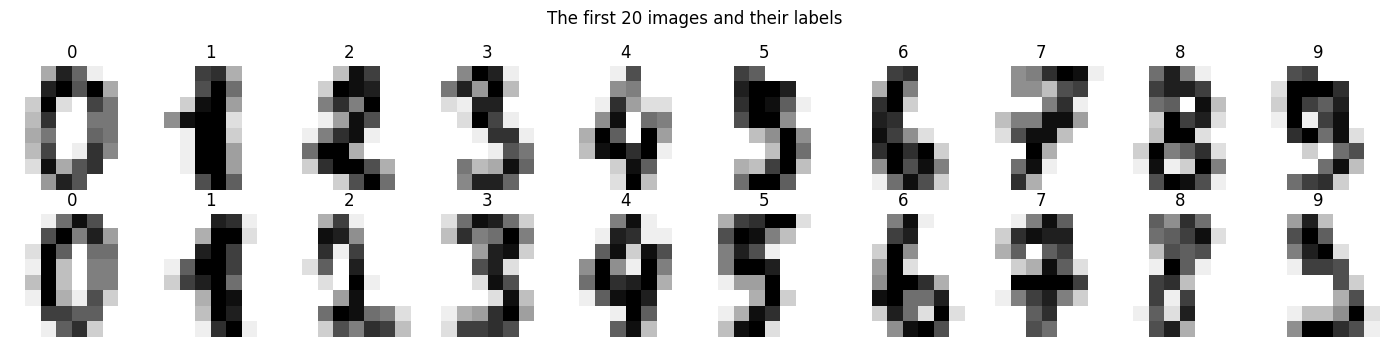

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits

digits = load_digits()
X = digits.data           # 1797 images, each flattened into 64 numbers (8 x 8 pixels)
y = digits.target         # the digit each image shows (0 to 9)
images = digits.images    # the same pixels shaped 8 x 8 (handy for drawing)

print('Images:', X.shape[0], '| pixels per image:', X.shape[1], '| image shape:', images.shape[1:])
print('Pixel brightness goes from', X.min(), 'to', X.max())

fig, axes = plt.subplots(2, 10, figsize=(14, 3.6))
for ax, img, label in zip(axes.ravel(), images, y):
    ax.imshow(img, cmap='gray_r')
    ax.set_title(label)
    ax.axis('off')
plt.suptitle('The first 20 images and their labels')
plt.tight_layout()
plt.show()

Images per digit:
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180

Pixels that are 0 in every single image: 3
Share of all pixel values that are exactly 0: 48.9%


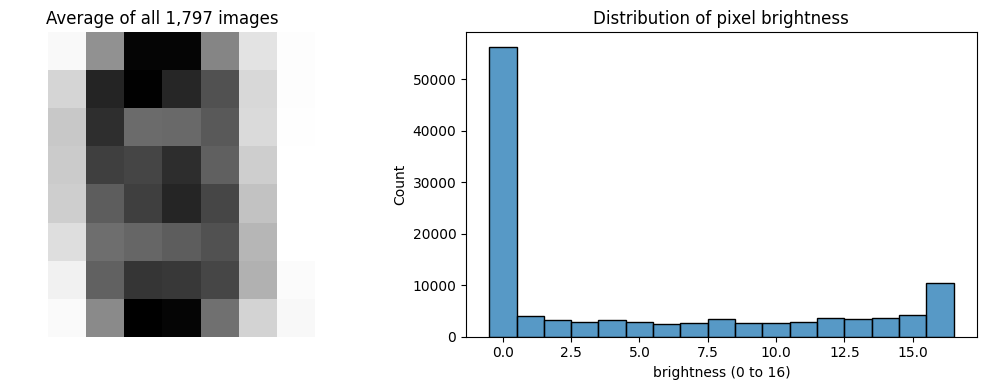

In [2]:
print('Images per digit:')
print(pd.Series(y).value_counts().sort_index().to_string())
print()

always_zero = int((X.max(axis=0) == 0).sum())
print('Pixels that are 0 in every single image:', always_zero)
print(f'Share of all pixel values that are exactly 0: {(X == 0).mean():.1%}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(X.mean(axis=0).reshape(8, 8), cmap='gray_r')
axes[0].set_title('Average of all 1,797 images')
axes[0].axis('off')
sns.histplot(X.ravel(), discrete=True, ax=axes[1])
axes[1].set_title('Distribution of pixel brightness')
axes[1].set_xlabel('brightness (0 to 16)')
plt.tight_layout()
plt.show()

In [3]:
std = X.std(axis=0)


def pixel_corr(i, j):
    if std[i] == 0 or std[j] == 0:
        return np.nan
    return abs(np.corrcoef(X[:, i], X[:, j])[0, 1])


# horizontal neighbours (pixel next to pixel in the same row)
neighbours = [pixel_corr(r * 8 + c, r * 8 + c + 1) for r in range(8) for c in range(7)]

# random pairs of pixels that are far apart (at least 4 steps)
rng = np.random.default_rng(0)
distant = []
while len(distant) < 200:
    i, j = rng.integers(0, 64, 2)
    if abs(i // 8 - j // 8) + abs(i % 8 - j % 8) >= 4:
        distant.append(pixel_corr(i, j))

print('Average absolute correlation between neighbouring pixels:', round(np.nanmean(neighbours), 2))
print('Average absolute correlation between distant pixels     :', round(np.nanmean(distant), 2))

Average absolute correlation between neighbouring pixels: 0.33
Average absolute correlation between distant pixels     : 0.09


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print('Training images:', len(X_train), '| Test images:', len(X_test))

Training images: 1347 | Test images: 450


In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB

default_models = {
    'Baseline (guess the most common digit)': DummyClassifier(strategy='most_frequent'),
    'GaussianNB (default)': GaussianNB(),
    'MultinomialNB (default)': MultinomialNB(),
    'BernoulliNB (default)': BernoulliNB(),
}

rows = []
for name, m in default_models.items():
    m.fit(X_train, y_train)
    rows.append({'model': name,
                 'train accuracy': m.score(X_train, y_train),
                 'test accuracy': m.score(X_test, y_test)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

                                 model  train accuracy  test accuracy
Baseline (guess the most common digit)           0.102          0.102
                  GaussianNB (default)           0.847          0.829
               MultinomialNB (default)           0.907          0.882
                 BernoulliNB (default)           0.867          0.844


In [6]:
classes = np.unique(y_train)
means = np.array([X_train[y_train == c].mean(axis=0) for c in classes])       # 10 digits x 64 pixels
variances = np.array([X_train[y_train == c].var(axis=0) for c in classes])    # 10 digits x 64 pixels
priors = np.array([(y_train == c).mean() for c in classes])                   # how common each digit is


def my_gaussian_nb(X_new, var_smoothing=1e-9):
    # scikit-learn adds a tiny fraction of the largest variance to every variance, for stability
    eps = var_smoothing * X_train.var(axis=0).max()
    var = variances + eps
    # log of the bell-curve density of every pixel, for every digit
    log_pdf = (-0.5 * np.log(2 * np.pi * var)[None, :, :]
               - 0.5 * (X_new[:, None, :] - means[None, :, :]) ** 2 / var[None, :, :])
    scores = np.log(priors)[None, :] + log_pdf.sum(axis=2)       # log prior + sum over the 64 pixels
    return classes[scores.argmax(axis=1)], scores


my_pred, _ = my_gaussian_nb(X_test)
sk_gnb = default_models['GaussianNB (default)']

print('From-scratch accuracy   :', round((my_pred == y_test).mean(), 3))
print('scikit-learn accuracy   :', round(sk_gnb.score(X_test, y_test), 3))
print('Identical predictions   :', round((my_pred == sk_gnb.predict(X_test)).mean() * 100, 1), '%')
print('Same means as sklearn   :', np.allclose(means, sk_gnb.theta_))

# why is the default setting weak?
n_zero_var = int((variances == 0).sum())
eps = 1e-9 * X_train.var(axis=0).max()
print()
print(f'(digit, pixel) combinations that were ALWAYS 0 in training: {n_zero_var} of {variances.size}')
print(f'For those, the variance is only about {eps:.0e}. If a test image has brightness 1 there,')
print(f'that single pixel costs about {0.5 * 1 / eps:,.0f} log-points, while a normal pixel costs only a few.')

From-scratch accuracy   : 0.829
scikit-learn accuracy   : 0.829
Identical predictions   : 100.0 %
Same means as sklearn   : True

(digit, pixel) combinations that were ALWAYS 0 in training: 131 of 640
For those, the variance is only about 4e-08. If a test image has brightness 1 there,
that single pixel costs about 11,792,098 log-points, while a normal pixel costs only a few.


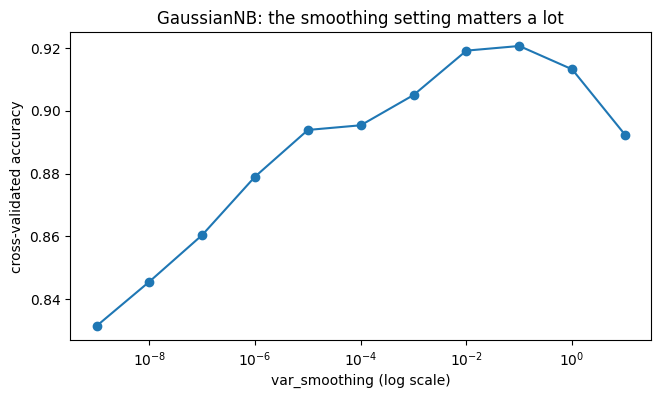

GaussianNB    best var_smoothing: 0.1
MultinomialNB best settings     : {'alpha': 5}
BernoulliNB   best settings     : {'alpha': 0.1, 'binarize': 6}

                model  CV accuracy  test accuracy
   GaussianNB (tuned)        0.921          0.916
MultinomialNB (tuned)        0.899          0.882
  BernoulliNB (tuned)        0.888          0.891


In [7]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# GaussianNB: try var_smoothing from 1e-9 up to 10
var_values = np.logspace(-9, 1, 11)
gauss_cv = [cross_val_score(GaussianNB(var_smoothing=v), X_train, y_train, cv=cv).mean() for v in var_values]

plt.figure(figsize=(7.5, 4))
plt.semilogx(var_values, gauss_cv, marker='o')
plt.xlabel('var_smoothing (log scale)')
plt.ylabel('cross-validated accuracy')
plt.title('GaussianNB: the smoothing setting matters a lot')
plt.show()

best_var = float(var_values[int(np.argmax(gauss_cv))])

mnb_grid = GridSearchCV(MultinomialNB(), {'alpha': [0.01, 0.1, 0.5, 1, 2, 5]}, cv=cv).fit(X_train, y_train)
bnb_grid = GridSearchCV(BernoulliNB(), {'alpha': [0.1, 0.5, 1, 2],
                                        'binarize': [0, 2, 4, 6, 8, 10]}, cv=cv).fit(X_train, y_train)

print('GaussianNB    best var_smoothing:', best_var)
print('MultinomialNB best settings     :', mnb_grid.best_params_)
print('BernoulliNB   best settings     :', bnb_grid.best_params_)

tuned = {
    'GaussianNB (tuned)': GaussianNB(var_smoothing=best_var).fit(X_train, y_train),
    'MultinomialNB (tuned)': mnb_grid.best_estimator_,
    'BernoulliNB (tuned)': bnb_grid.best_estimator_,
}
cv_scores = {
    'GaussianNB (tuned)': max(gauss_cv),
    'MultinomialNB (tuned)': mnb_grid.best_score_,
    'BernoulliNB (tuned)': bnb_grid.best_score_,
}

rows = []
for name, m in tuned.items():
    rows.append({'model': name, 'CV accuracy': cv_scores[name], 'test accuracy': m.score(X_test, y_test)})
print()
print(pd.DataFrame(rows).round(3).to_string(index=False))

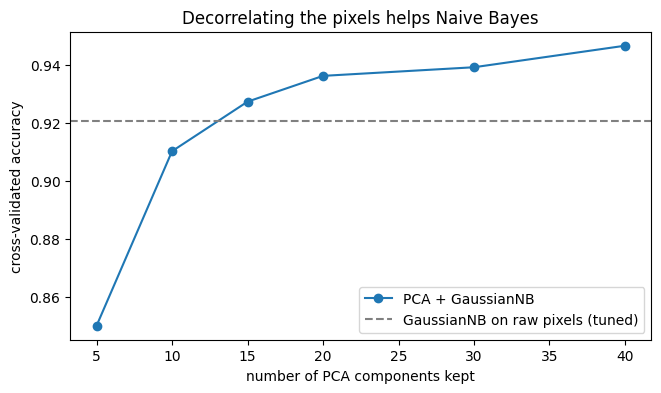

Best number of components: 40
PCA + GaussianNB  CV accuracy: 0.947 | test accuracy: 0.949
GaussianNB (tuned) CV accuracy: 0.921

Best Naive Bayes model by cross-validation: PCA + GaussianNB


In [8]:
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

n_list = [5, 10, 15, 20, 30, 40]
pca_cv = [cross_val_score(make_pipeline(PCA(n_components=n), GaussianNB()), X_train, y_train, cv=cv).mean()
          for n in n_list]

plt.figure(figsize=(7.5, 4))
plt.plot(n_list, pca_cv, marker='o', label='PCA + GaussianNB')
plt.axhline(max(gauss_cv), color='gray', linestyle='--', label='GaussianNB on raw pixels (tuned)')
plt.xlabel('number of PCA components kept')
plt.ylabel('cross-validated accuracy')
plt.title('Decorrelating the pixels helps Naive Bayes')
plt.legend()
plt.show()

best_n = n_list[int(np.argmax(pca_cv))]
pca_model = make_pipeline(PCA(n_components=best_n), GaussianNB()).fit(X_train, y_train)
tuned['PCA + GaussianNB'] = pca_model
cv_scores['PCA + GaussianNB'] = max(pca_cv)

print('Best number of components:', best_n)
print('PCA + GaussianNB  CV accuracy:', round(max(pca_cv), 3), '| test accuracy:', round(pca_model.score(X_test, y_test), 3))
print('GaussianNB (tuned) CV accuracy:', round(max(gauss_cv), 3))

# the overall winner among all the Naive Bayes models, chosen by CROSS-VALIDATION (not by the test set)
best_name = max(cv_scores, key=cv_scores.get)
best_model = tuned[best_name]
print()
print('Best Naive Bayes model by cross-validation:', best_name)

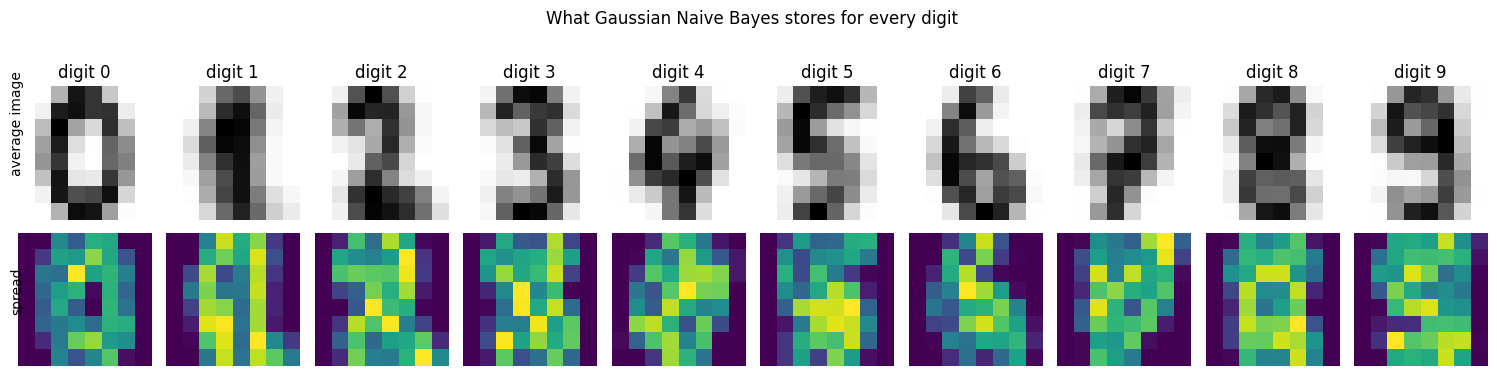

In [9]:
gnb_tuned = tuned['GaussianNB (tuned)']

fig, axes = plt.subplots(2, 10, figsize=(15, 3.8))
for d in range(10):
    axes[0, d].imshow(gnb_tuned.theta_[d].reshape(8, 8), cmap='gray_r')
    axes[0, d].set_title(f'digit {d}')
    axes[0, d].axis('off')
    axes[1, d].imshow(np.sqrt(gnb_tuned.var_[d]).reshape(8, 8), cmap='viridis')
    axes[1, d].axis('off')
fig.text(0.005, 0.72, 'average image', rotation=90, va='center')
fig.text(0.005, 0.28, 'spread', rotation=90, va='center')
plt.suptitle('What Gaussian Naive Bayes stores for every digit', y=1.02)
plt.tight_layout()
plt.show()

Model: PCA + GaussianNB
Test accuracy: 0.949

              precision    recall  f1-score   support

           0      1.000     0.933     0.966        45
           1      0.882     0.978     0.928        46
           2      1.000     0.955     0.977        44
           3      1.000     0.935     0.966        46
           4      0.978     0.978     0.978        45
           5      0.953     0.891     0.921        46
           6      1.000     0.956     0.977        45
           7      0.938     1.000     0.968        45
           8      0.930     0.930     0.930        43
           9      0.840     0.933     0.884        45

    accuracy                          0.949       450
   macro avg      0.952     0.949     0.949       450
weighted avg      0.952     0.949     0.949       450



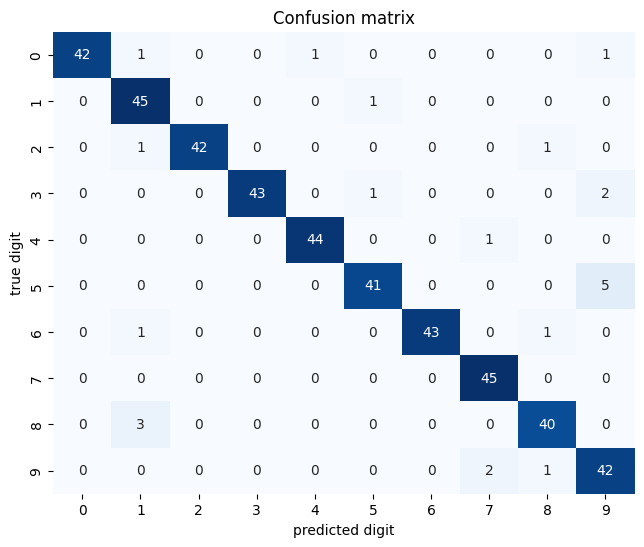

Most common mistakes:
   a real 5 was read as a 9: 5 time(s)
   a real 8 was read as a 1: 3 time(s)
   a real 3 was read as a 9: 2 time(s)
   a real 9 was read as a 7: 2 time(s)
   a real 0 was read as a 1: 1 time(s)


In [10]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

pred = best_model.predict(X_test)
print(f'Model: {best_name}')
print('Test accuracy:', round(accuracy_score(y_test, pred), 3))
print()
print(classification_report(y_test, pred, digits=3))

cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(7.5, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('predicted digit')
plt.ylabel('true digit')
plt.title('Confusion matrix')
plt.show()

off = cm.copy()
np.fill_diagonal(off, 0)
pairs = sorted([(i, j, off[i, j]) for i in range(10) for j in range(10) if off[i, j] > 0], key=lambda t: -t[2])
print('Most common mistakes:')
for i, j, n in pairs[:5]:
    print(f'   a real {i} was read as a {j}: {n} time(s)')

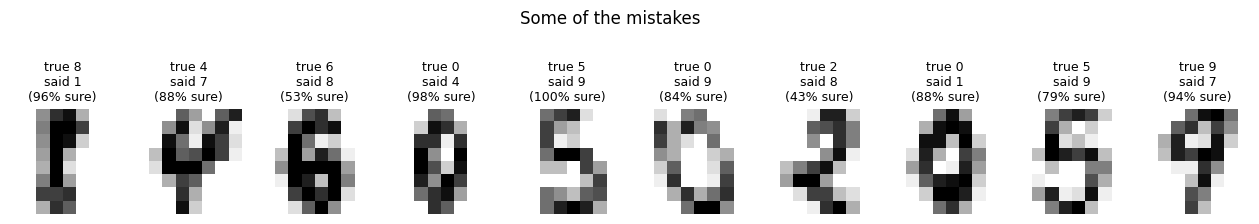

How trustworthy is the confidence?
            images  accuracy  average_confidence
confidence                                      
under 50%        1     0.000               0.431
50% to 90%      34     0.647               0.733
90% to 99%      52     0.865               0.966
over 99%       363     0.992               0.999


In [11]:
proba = best_model.predict_proba(X_test)
confidence = proba.max(axis=1)
wrong = np.where(pred != y_test)[0]

n_show = min(10, len(wrong))
if n_show:
    fig, axes = plt.subplots(1, n_show, figsize=(1.6 * n_show, 2.6))
    axes = np.atleast_1d(axes)
    for ax, idx in zip(axes, wrong[:n_show]):
        ax.imshow(X_test[idx].reshape(8, 8), cmap='gray_r')
        ax.set_title(f'true {y_test[idx]}\nsaid {pred[idx]}\n({confidence[idx]:.0%} sure)', fontsize=9)
        ax.axis('off')
    plt.suptitle('Some of the mistakes', y=1.08)
    plt.show()

labels = ['under 50%', '50% to 90%', '90% to 99%', 'over 99%']
bins = pd.cut(confidence, bins=[0, 0.5, 0.9, 0.99, 1.0000001], labels=labels, right=False)
reliability = (pd.DataFrame({'confidence': bins, 'correct': pred == y_test, 'conf': confidence})
               .groupby('confidence', observed=False)
               .agg(images=('correct', 'size'), accuracy=('correct', 'mean'), average_confidence=('conf', 'mean')))
print('How trustworthy is the confidence?')
print(reliability.round(3).to_string())

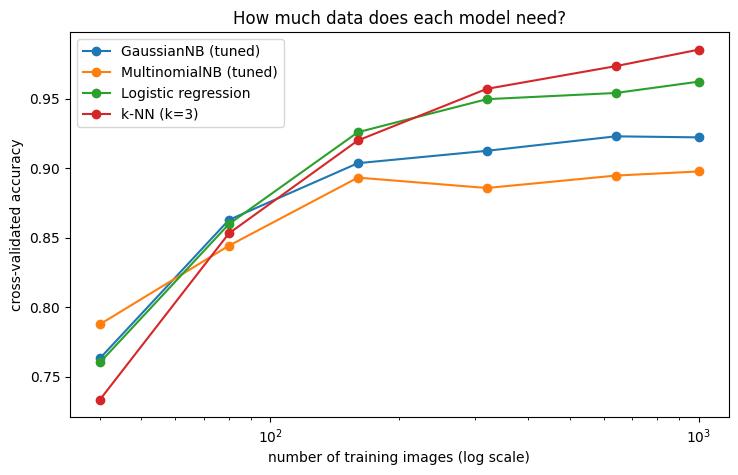

Accuracy with only 40 training images  ->  with 1000 training images
   GaussianNB (tuned)       0.763  ->  0.922
   MultinomialNB (tuned)    0.788  ->  0.898
   Logistic regression      0.760  ->  0.962
   k-NN (k=3)               0.733  ->  0.985


In [12]:
from sklearn.model_selection import learning_curve
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

curve_models = {
    'GaussianNB (tuned)': GaussianNB(var_smoothing=best_var),
    'MultinomialNB (tuned)': mnb_grid.best_estimator_,
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    'k-NN (k=3)': KNeighborsClassifier(n_neighbors=3),
}
sizes = [40, 80, 160, 320, 640, 1000]

plt.figure(figsize=(8.5, 5))
final_scores = {}
for name, m in curve_models.items():
    sz, _, val = learning_curve(m, X_train, y_train, train_sizes=sizes, cv=cv,
                                scoring='accuracy', shuffle=True, random_state=42)
    plt.plot(sz, val.mean(axis=1), marker='o', label=name)
    final_scores[name] = (val.mean(axis=1)[0], val.mean(axis=1)[-1])

plt.xscale('log')
plt.xlabel('number of training images (log scale)')
plt.ylabel('cross-validated accuracy')
plt.title('How much data does each model need?')
plt.legend()
plt.show()

print('Accuracy with only 40 training images  ->  with 1000 training images')
for name, (small, large) in final_scores.items():
    print(f'   {name:<24} {small:.3f}  ->  {large:.3f}')

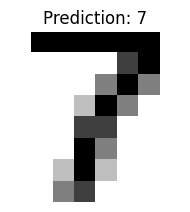

Top guesses: 7 (100%), 8 (0%), 5 (0%)


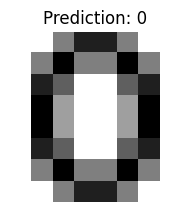

Top guesses: 0 (99%), 9 (1%), 5 (0%)


In [13]:
def predict_digit(grid, model=best_model):
    pixels = np.array(grid, dtype=float).reshape(1, 64)
    p = model.predict_proba(pixels)[0]
    top3 = np.argsort(-p)[:3]

    plt.figure(figsize=(2.2, 2.4))
    plt.imshow(pixels.reshape(8, 8), cmap='gray_r', vmin=0, vmax=16)
    plt.title(f'Prediction: {top3[0]}')
    plt.axis('off')
    plt.show()
    print('Top guesses:', ', '.join(f'{d} ({p[d]:.0%})' for d in top3))


seven = [
    [0, 16, 16, 16, 16, 16, 16, 0],
    [0, 0, 0, 0, 0, 12, 16, 0],
    [0, 0, 0, 0, 8, 16, 8, 0],
    [0, 0, 0, 4, 16, 8, 0, 0],
    [0, 0, 0, 12, 12, 0, 0, 0],
    [0, 0, 0, 16, 8, 0, 0, 0],
    [0, 0, 4, 16, 4, 0, 0, 0],
    [0, 0, 8, 12, 0, 0, 0, 0],
]

zero = [
    [0, 0, 8, 14, 14, 8, 0, 0],
    [0, 8, 16, 8, 8, 16, 8, 0],
    [0, 14, 10, 0, 0, 10, 14, 0],
    [0, 16, 6, 0, 0, 6, 16, 0],
    [0, 16, 6, 0, 0, 6, 16, 0],
    [0, 14, 10, 0, 0, 10, 14, 0],
    [0, 8, 16, 8, 8, 16, 8, 0],
    [0, 0, 8, 14, 14, 8, 0, 0],
]

predict_digit(seven)
predict_digit(zero)

In [14]:
df_digits = pd.DataFrame(X, columns=[f'pixel_{r}_{c}' for r in range(8) for c in range(8)])
df_digits['digit'] = y
df_digits.to_csv('digits.csv', index=False)
print('Saved digits.csv with', df_digits.shape[0], 'rows and', df_digits.shape[1], 'columns')

try:
    from google.colab import files
    files.download('digits.csv')
except ImportError:
    print('(Not running in Colab: the file was saved in the current folder.)')

Saved digits.csv with 1797 rows and 65 columns


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>